# Module A validation: framing, features, frame classification

In [1]:
import os, sys
root = os.getcwd()
while not os.path.exists(os.path.join(root, 'src', 'framing.py')) and os.path.dirname(root) != root:
    root = os.path.dirname(root)
sys.path.insert(0, root)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from src.framing import load_audio, frame_signal, frame_energy, frame_zcr
from src.detect import voicing_strength, calibrate_thresholds, classify_frames
from tests.fixtures import pseudo_whisper
plt.rcParams['figure.figsize'] = (7, 3)
plt.rcParams['figure.dpi'] = 80
shared = os.path.join(root, 'data', 'raw', 'shared_test.wav')
if os.path.exists(shared):
    x, fs = load_audio(shared)
    xv = None
    source = 'data/raw/shared_test.wav'
else:
    x, fs = pseudo_whisper()
    source = 'pseudo_whisper fixture'
xw, _ = pseudo_whisper()
xv, _ = pseudo_whisper(voiced=True)
print('source:', source, 'samples:', len(x), 'fs:', fs)

source: pseudo_whisper fixture samples: 41120 fs: 16000


## A1 Load and waveform

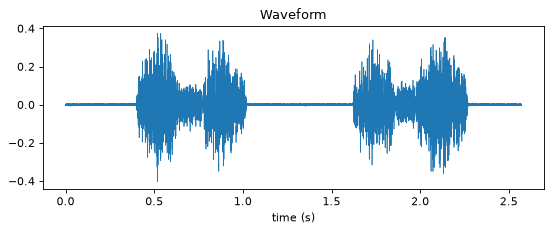

float32 1 16000


In [2]:
t = np.arange(len(x)) / fs
plt.plot(t, x, lw=0.6)
plt.xlabel('time (s)'); plt.title('Waveform')
plt.tight_layout(); plt.show()
print(x.dtype, x.ndim, fs)

## A2 Framing against librosa

In [3]:
frames = frame_signal(x)
ref = librosa.util.frame(x, frame_length=320, hop_length=160).T
print('shape', frames.shape, 'expected n_frames', 1 + (len(x) - 320) // 160)
print('identical to librosa.util.frame:', np.array_equal(frames, ref))

shape (256, 320) expected n_frames 256
identical to librosa.util.frame: True


## A3 RMS and ZCR against librosa

In [4]:
energy = frame_energy(frames)
zcr = frame_zcr(frames)
rms_ref = librosa.feature.rms(y=x, frame_length=320, hop_length=160, center=False)[0]
zcr_ref = librosa.feature.zero_crossing_rate(x, frame_length=320, hop_length=160, center=False)[0]
print('max abs diff RMS:', np.abs(energy - rms_ref).max())
print('max abs diff ZCR (raw):', np.abs(zcr - zcr_ref).max())
print('max abs diff ZCR (scaled by 319/320):', np.abs(zcr * 319 / 320 - zcr_ref).max())

C:\Users\raksh\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


max abs diff RMS: 0.0
max abs diff ZCR (raw): 0.0023315047021943425
max abs diff ZCR (scaled by 319/320): 1.1102230246251565e-16


## A4 Voicing strength

120 Hz sine, mean strength: 0.99987674
white noise, mean strength: 0.21698037


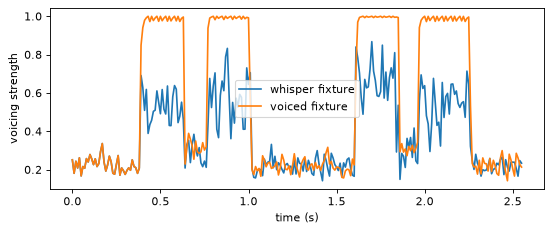

In [5]:
tt = np.arange(8000) / 16000
sine = np.sin(2 * np.pi * 120 * tt).astype(np.float32)
noise = np.random.default_rng(1).standard_normal(8000).astype(np.float32)
print('120 Hz sine, mean strength:', voicing_strength(frame_signal(sine)).mean())
print('white noise, mean strength:', voicing_strength(frame_signal(noise)).mean())
vw = voicing_strength(frame_signal(xw))
vv = voicing_strength(frame_signal(xv))
plt.plot(np.arange(len(vw)) * 0.01, vw, label='whisper fixture')
plt.plot(np.arange(len(vv)) * 0.01, vv, label='voiced fixture')
plt.xlabel('time (s)'); plt.ylabel('voicing strength'); plt.legend()
plt.tight_layout(); plt.show()

## A5 Frame labels and thresholds

silence_thr = 0.00583, zcr_thr = 0.138
label counts: {0: 117, 1: 47, 2: 92}


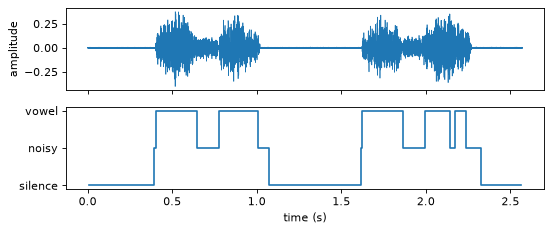

In [6]:
labels, zcr_thr, silence_thr = classify_frames(frames, energy, zcr, return_thresholds=True)
print('silence_thr = %.5f, zcr_thr = %.3f' % (silence_thr, zcr_thr))
print('label counts:', dict(zip(*[a.tolist() for a in np.unique(labels, return_counts=True)])))
ft = (np.arange(len(labels)) * 160 + 160) / fs
fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(t, x, lw=0.6); ax[0].set_ylabel('amplitude')
ax[1].step(ft, labels, where='mid'); ax[1].set_yticks([0, 1, 2])
ax[1].set_yticklabels(['silence', 'noisy', 'vowel']); ax[1].set_xlabel('time (s)')
plt.tight_layout(); plt.show()

## A6 Spectrograms: whisper vs voiced

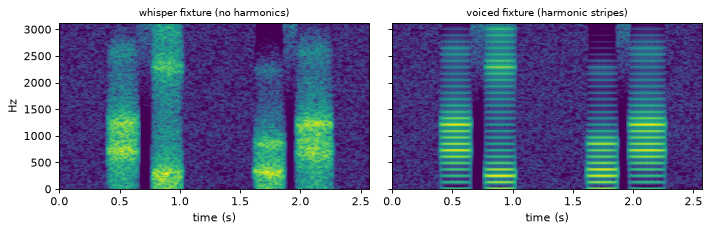

In [7]:
fig, ax = plt.subplots(1, 2, sharey=True, figsize=(9, 3))
for a, sig, name in zip(ax, (xw, xv), ('whisper fixture (no harmonics)', 'voiced fixture (harmonic stripes)')):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=1024, hop_length=160)), ref=np.max)
    a.imshow(S[:200], origin='lower', aspect='auto', extent=[0, len(sig) / 16000, 0, 200 * 16000 / 1024], vmin=-70, vmax=0)
    a.set_title(name, fontsize=9); a.set_xlabel('time (s)')
ax[0].set_ylabel('Hz')
plt.tight_layout(); plt.show()